# Open-Meteo weather data for Belgium: visual exploration

This notebook looks at the weather file on its own, before it is joined to solar output.

**File:** `weather_belgium.parquet`, built by `download_weather.py` from the Open-Meteo Historical Forecast API, ECMWF IFS HRES model (9 km).
One row per area per hour (column `time`, in UTC), for the 10 Belgian provinces plus Brussels, January 2021 to 25 October 2026.

**Sections**
1. What is in the file
2. Quality checks
3. Distribution of each variable
4. Patterns over time: seasons and time of day
5. A sample week, all variables
6. The working area against the others
7. How the features relate to each other

**The analysis is on one area, set by `PROVINCE` (Antwerp).** The file holds all eleven areas. Section 6 uses them to show how Antwerp compares with the rest. Change `PROVINCE` and `WEEK_START` in the first code cell to look at another area or period.
Needs `pandas`, `pyarrow`, `matplotlib`, `numpy`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WEATHER_FILE = Path("weather_belgium.parquet")
PROVINCE = "Antwerp"            # the area the analysis is run on
WEEK_START = "2025-06-16"       # first day of the sample week in section 5

# chart style
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, BLUE_LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.8, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. What is in the file

The 16 weather variables are the raw features of the project. Province and Elia's monitored capacity bring the count to 18.

In [2]:
wx_all = pd.read_parquet(WEATHER_FILE).sort_values(["region", "time"]).reset_index(drop=True)    # every area
wx = wx_all[wx_all["region"] == PROVINCE].reset_index(drop=True)                                 # the working area

VARIABLES = {   # column: (label, unit, group)
    "shortwave_radiation": ("Global horizontal irradiance", "W/m²", "Sunlight"),
    "direct_radiation": ("Direct irradiance (horizontal)", "W/m²", "Sunlight"),
    "diffuse_radiation": ("Diffuse irradiance", "W/m²", "Sunlight"),
    "direct_normal_irradiance": ("Direct normal irradiance", "W/m²", "Sunlight"),
    "cloud_cover": ("Cloud cover, total", "%", "Cloud"),
    "cloud_cover_low": ("Cloud cover, low", "%", "Cloud"),
    "cloud_cover_mid": ("Cloud cover, mid", "%", "Cloud"),
    "cloud_cover_high": ("Cloud cover, high", "%", "Cloud"),
    "temperature_2m": ("Air temperature", "°C", "Air"),
    "dew_point_2m": ("Dew point", "°C", "Air"),
    "relative_humidity_2m": ("Relative humidity", "%", "Air"),
    "surface_pressure": ("Surface pressure", "hPa", "Air"),
    "precipitation": ("Precipitation", "mm", "Air"),
    "wind_speed_10m": ("Wind speed", "km/h", "Wind"),
    "wind_gusts_10m": ("Wind gusts", "km/h", "Wind"),
    "wind_direction_10m": ("Wind direction", "°", "Wind"),
}
cols = [c for c in VARIABLES if c in wx.columns]
missing_cols = [c for c in VARIABLES if c not in wx.columns]
label = lambda c: f"{VARIABLES[c][0]} ({VARIABLES[c][1]})"

print(f"Whole file: {len(wx_all):,} rows, {wx_all['region'].nunique()} areas")
print(f"{PROVINCE}: {len(wx):,} rows   Weather variables: {len(cols)}")
print(f"Period: {wx['time'].min()}  to  {wx['time'].max()}")
if missing_cols:
    print(f"Not in this file (rerun download_weather.py): {missing_cols}")

summary = wx[cols].describe().T[["mean", "std", "min", "50%", "max"]].rename(columns={"50%": "median"})
summary.insert(0, "group", [VARIABLES[c][2] for c in cols])
summary.index = [label(c) for c in cols]
summary

Whole file: 560,736 rows, 11 areas
Antwerp: 50,976 rows   Weather variables: 16
Period: 2021-01-01 00:00:00+00:00  to  2026-10-25 23:00:00+00:00


,group,mean,std,min,median,max
Global horizontal irradiance (W/m²),Sunlight,137.11,208.55,0.00,7.00,892.00
Direct irradiance (horizontal) (W/m²),Sunlight,82.06,156.17,0.00,0.00,781.00
Diffuse irradiance (W/m²),Sunlight,55.05,76.79,0.00,6.00,427.00
Direct normal irradiance (W/m²),Sunlight,160.55,252.57,0.00,0.00,919.90
"Cloud cover, total (%)",Cloud,66.00,39.84,0.00,92.00,100.00
"Cloud cover, low (%)",Cloud,33.92,40.44,0.00,12.00,100.00
"Cloud cover, mid (%)",Cloud,31.92,39.29,0.00,9.00,100.00
"Cloud cover, high (%)",Cloud,41.31,44.16,0.00,16.00,100.00
Air temperature (°C),Air,11.92,7.06,-9.60,11.80,39.40
Dew point (°C),Air,7.59,5.59,-15.80,7.90,23.60


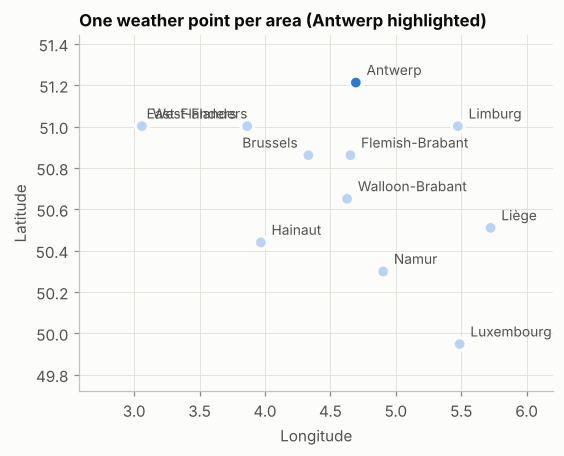

In [3]:
# The sampling point for each area
points = wx_all.groupby("region")[["latitude", "longitude"]].first()
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(points["longitude"], points["latitude"], s=70, zorder=3, edgecolor=SURFACE, linewidth=2,
           color=[BLUE if n == PROVINCE else BLUE_LIGHT for n in points.index])
for name, r in points.iterrows():
    left = name in ("Brussels", "East-Flanders")
    ax.annotate(name, (r["longitude"], r["latitude"]), xytext=(-7 if left else 7, 5), textcoords="offset points",
                ha="right" if left else "left", fontsize=9, color=INK2)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title(f"One weather point per area ({PROVINCE} highlighted)")
ax.set_aspect(1.58)   # roughly equal distances at 50.5°N
ax.margins(0.18)
plt.show()

## 2. Quality checks

Three questions: is every hour present, are any values missing, and are the values physically possible?

In [4]:
expected = int((wx["time"].max() - wx["time"].min()) / pd.Timedelta("1h")) + 1
per_area = wx.groupby("region").size()
print(f"Hours per area: expected {expected:,}, found {per_area.min():,} to {per_area.max():,}")
print(f"Duplicate (area, hour) rows: {wx.duplicated(['region', 'time']).sum()}")
print(f"Missing values in total: {int(wx[cols].isna().sum().sum())}")

LIMITS = {   # column: (lowest plausible, highest plausible) for Belgium
    "shortwave_radiation": (0, 1100), "direct_radiation": (0, 1000), "diffuse_radiation": (0, 700), "direct_normal_irradiance": (0, 1100),
    "cloud_cover": (0, 100), "cloud_cover_low": (0, 100), "cloud_cover_mid": (0, 100), "cloud_cover_high": (0, 100),
    "temperature_2m": (-25, 45), "dew_point_2m": (-25, 30), "relative_humidity_2m": (10, 100), "surface_pressure": (900, 1060),
    "precipitation": (0, 60), "wind_speed_10m": (0, 130), "wind_gusts_10m": (0, 200), "wind_direction_10m": (0, 360),
}
out = pd.DataFrame({label(c): {"below": int((wx[c] < LIMITS[c][0]).sum()), "above": int((wx[c] > LIMITS[c][1]).sum()),
                               "plausible range": f"{LIMITS[c][0]} to {LIMITS[c][1]}"} for c in cols}).T
out[(out["below"] > 0) | (out["above"] > 0)] if ((out["below"] > 0) | (out["above"] > 0)).any() else "All values inside plausible ranges"

Hours per area: expected 50,976, found 50,976 to 50,976
Duplicate (area, hour) rows: 0
Missing values in total: 0


'All values inside plausible ranges'

In [5]:
# When do the implausible values occur? Flag them, list the days, then blank them out.
flag = pd.Series(False, index=wx.index)
for c in cols:
    flag |= (wx[c] < LIMITS[c][0]) | (wx[c] > LIMITS[c][1])
print(f"Rows with at least one implausible value: {flag.sum():,} ({flag.mean():.2%})")

if flag.any():
    bad_cols = [c for c in cols if ((wx[c] < LIMITS[c][0]) | (wx[c] > LIMITS[c][1])).any()]
    days = wx[flag].groupby(wx.loc[flag, "time"].dt.date).agg(rows=("region", "size"), areas=("region", "nunique"))
    print(f"Affected variables: {[VARIABLES[c][0] for c in bad_cols]}")
    display(days)
    for c in bad_cols:
        wx.loc[(wx[c] < LIMITS[c][0]) | (wx[c] > LIMITS[c][1]), c] = np.nan
    print("These values are now set to missing in this notebook. Do the same in the modelling notebook.")

Rows with at least one implausible value: 0 (0.00%)


In [6]:
# Physics checks on the sunlight variables
night = wx[wx["time"].dt.hour.isin([23, 0, 1])]
gap = (wx["direct_radiation"] + wx["diffuse_radiation"] - wx["shortwave_radiation"]).abs()
print(f"Irradiance above zero around midnight UTC: {(night['shortwave_radiation'] > 0).mean():.2%} of rows")
print(f"Direct + diffuse against global irradiance: largest gap {gap.max():.1f} W/m²")
print(f"Hours where a cloud layer exceeds total cloud by more than 1 point: "
      f"{(wx[['cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high']].max(axis=1) > wx['cloud_cover'] + 1).mean():.2%}")
if "wind_gusts_10m" in wx:
    print(f"Hours where gusts are below mean wind speed: {(wx['wind_gusts_10m'] < wx['wind_speed_10m'] - 0.5).mean():.2%}")
if "dew_point_2m" in wx:
    print(f"Hours where dew point is above air temperature: {(wx['dew_point_2m'] > wx['temperature_2m'] + 0.5).mean():.2%}")

Irradiance above zero around midnight UTC: 0.00% of rows
Direct + diffuse against global irradiance: largest gap 0.0 W/m²
Hours where a cloud layer exceeds total cloud by more than 1 point: 1.18%
Hours where gusts are below mean wind speed: 0.03%
Hours where dew point is above air temperature: 0.00%


## 3. Distribution of each variable

Sunlight variables are shown for daylight hours only, since half of all hours are zero. Precipitation is shown for wet hours only, for the same reason.

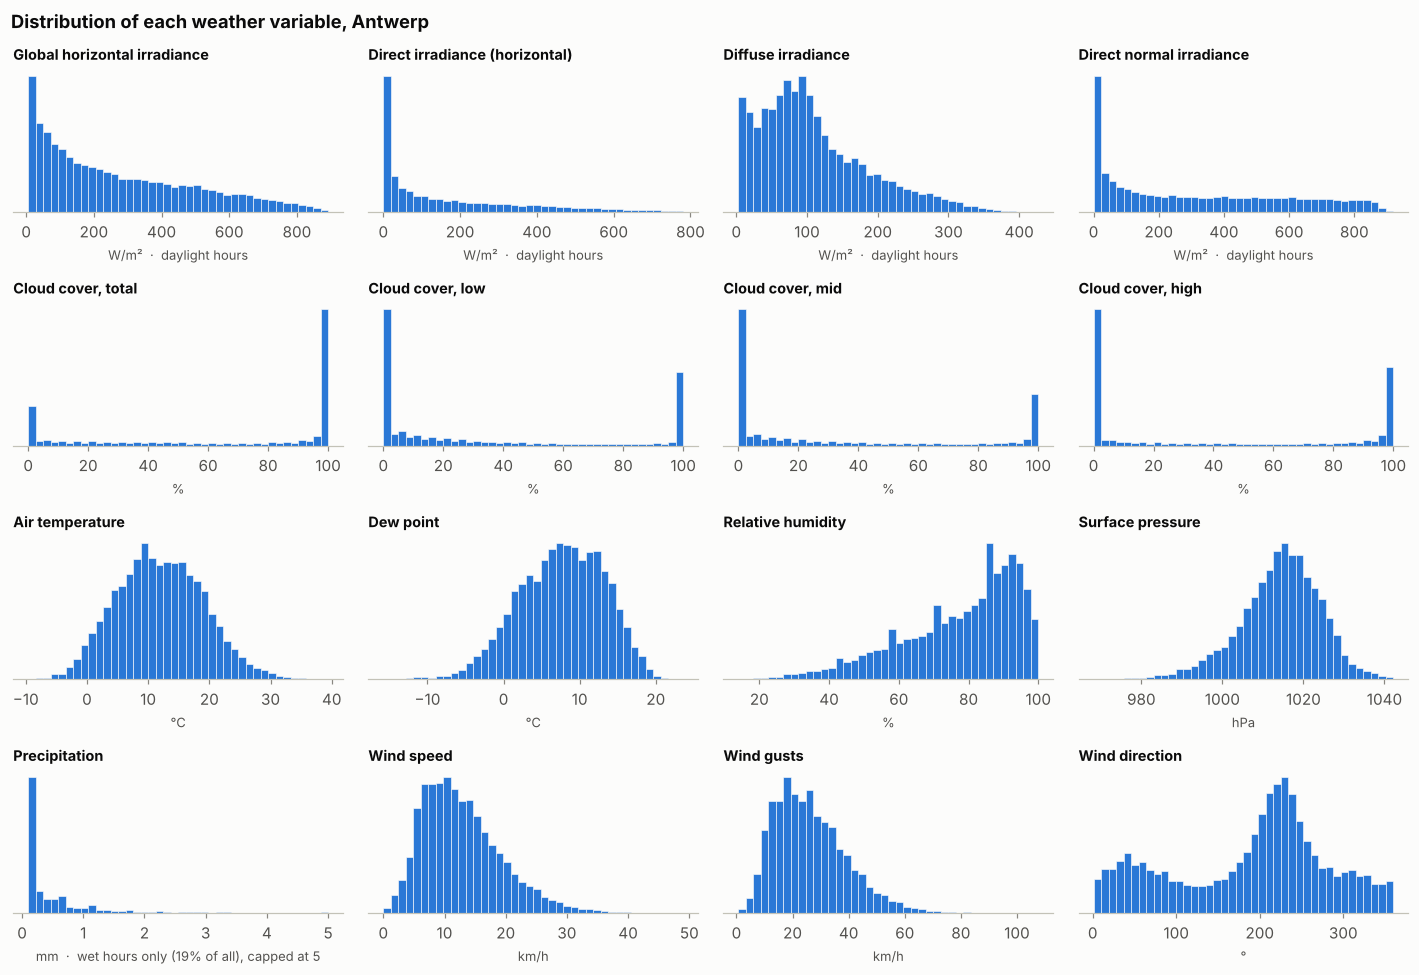

In [7]:
day = wx[wx["shortwave_radiation"] > 5]
fig, axes = plt.subplots(4, 4, figsize=(13, 9))
for ax, c in zip(axes.ravel(), cols):
    data = wx[c].dropna()
    note = ""
    if VARIABLES[c][2] == "Sunlight":
        data, note = day[c].dropna(), "daylight hours"
    elif c == "precipitation":
        data, note = data[data > 0].clip(upper=5), f"wet hours only ({(wx[c] > 0).mean():.0%} of all), capped at 5"
    ax.hist(data, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    ax.set_title(VARIABLES[c][0], fontsize=9.5)
    ax.set_xlabel(f"{VARIABLES[c][1]}" + (f"  ·  {note}" if note else ""), fontsize=8.5)
    ax.set_yticks([]); ax.grid(False)
    ax.spines["left"].set_visible(False)
for ax in axes.ravel()[len(cols):]:
    ax.set_visible(False)
fig.suptitle(f"Distribution of each weather variable, {PROVINCE}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

### 3.1 Cloud cover in detail

In the grid above, the bars at 0% and 100% are so tall that the values in between look empty. They are not. This chart uses ten wide bands and prints the share of hours in each, for daylight hours only, since cloud at night does not affect solar output.

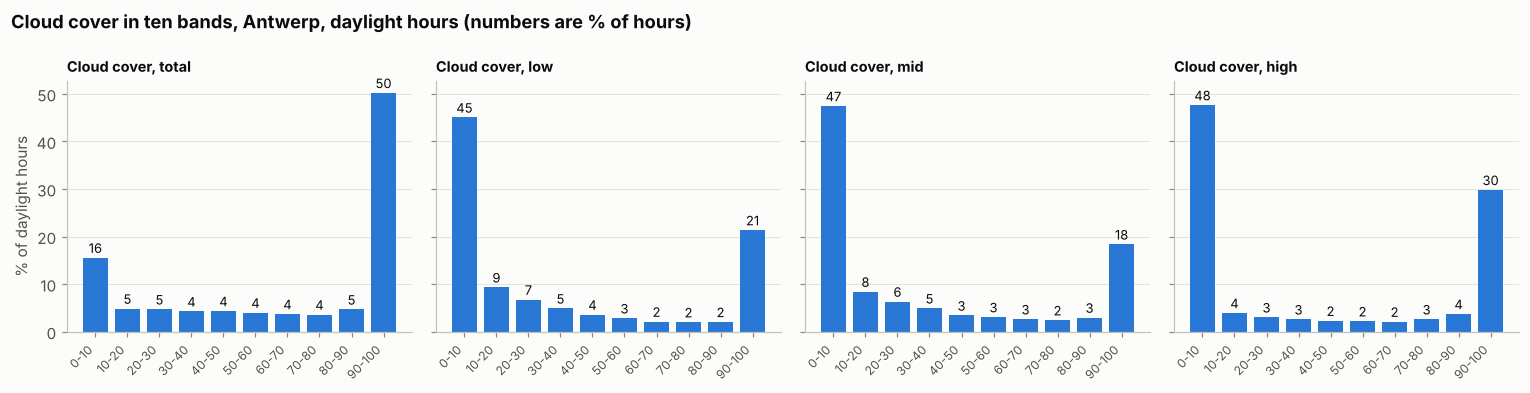

,exactly 0 %,"partial (above 0, below 100) %",exactly 100 %
"Cloud cover, total",9.49,52.96,37.55
"Cloud cover, low",29.72,52.86,17.42
"Cloud cover, mid",33.85,54.37,11.78
"Cloud cover, high",39.51,41.93,18.56


In [8]:
cloud_cols = [c for c in ["cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high"] if c in cols]
dl = wx[wx["shortwave_radiation"] > 5]
edges = np.arange(0, 101, 10)
bands = [f"{lo}-{lo + 10}" for lo in edges[:-1]]

fig, axes = plt.subplots(1, len(cloud_cols), figsize=(14, 3.6), sharey=True)
for ax, c in zip(axes, cloud_cols):
    share = np.histogram(dl[c].dropna(), bins=edges)[0] / dl[c].notna().sum() * 100
    ax.bar(range(10), share, color=BLUE, width=0.8)
    for x, v in enumerate(share):
        ax.text(x, v + 1, f"{v:.0f}", ha="center", fontsize=8.5, color=INK)
    ax.set_xticks(range(10), bands, rotation=45, ha="right", fontsize=8)
    ax.set_title(VARIABLES[c][0], fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of daylight hours")
fig.suptitle(f"Cloud cover in ten bands, {PROVINCE}, daylight hours (numbers are % of hours)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

def spread(s):
    return pd.Series({"exactly 0 %": (s == 0).mean() * 100, "partial (above 0, below 100) %": ((s > 0) & (s < 100)).mean() * 100,
                      "exactly 100 %": (s == 100).mean() * 100})
pd.DataFrame({VARIABLES[c][0]: spread(dl[c].dropna()) for c in cloud_cols}).T

The same split by year. If the weather model behind the archive had stayed the same, these shares would move only a little from year to year.

In [9]:
by_year = {c: dl.groupby(dl["time"].dt.year)[c].apply(lambda s: ((s > 0) & (s < 100)).mean() * 100) for c in cloud_cols}
out = pd.DataFrame(by_year).rename(columns={c: VARIABLES[c][0] for c in cloud_cols})
out.index.name = "share of daylight hours with partial cloud, %"
out

,"Cloud cover, total","Cloud cover, low","Cloud cover, mid","Cloud cover, high"
"share of daylight hours with partial cloud, %",,,,
2021,63.57,62.26,60.96,49.74
2022,48.84,47.81,49.89,37.07
2023,46.08,49.61,54.45,37.24
2024,48.06,59.01,56.86,40.64
2025,50.64,49.36,48.57,35.85
2026,61.64,48.61,55.68,52.33


## 4. Patterns over time

### 4.1 Month by month

Each panel has its own scale. Look for the yearly cycle and for anything that breaks it.

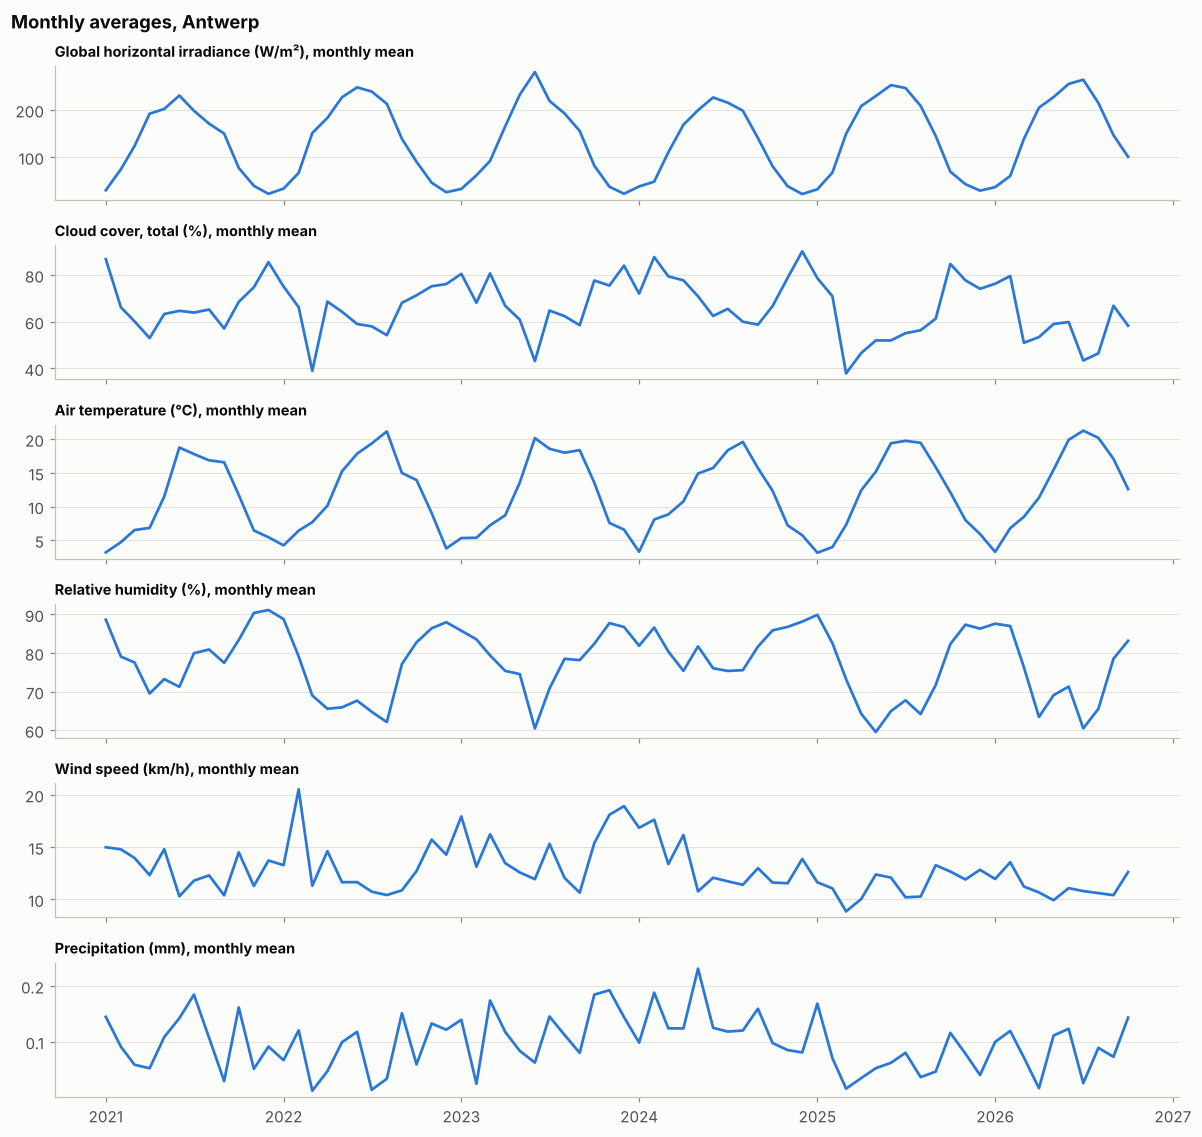

In [10]:
one = wx[wx["region"] == PROVINCE].set_index("time")
monthly = one[cols].resample("MS").mean()
panels = ["shortwave_radiation", "cloud_cover", "temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation"]
panels = [c for c in panels if c in cols]

fig, axes = plt.subplots(len(panels), 1, figsize=(11, 1.75 * len(panels)), sharex=True)
for ax, c in zip(axes, panels):
    ax.plot(monthly.index, monthly[c], color=BLUE)
    ax.set_title(label(c) + ", monthly mean", fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle(f"Monthly averages, {PROVINCE}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

### 4.2 Irradiance by month and hour

This is the shape the model has to learn before clouds enter: long bright days in summer, short dim days in winter.

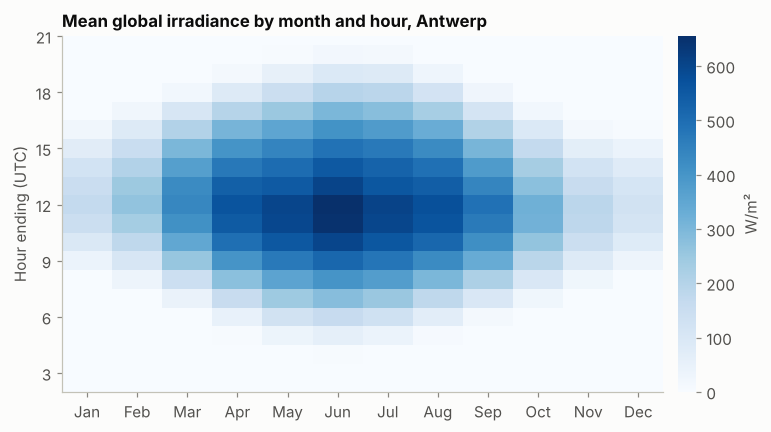

In [11]:
grid = one.pivot_table(index=one.index.hour, columns=one.index.month, values="shortwave_radiation", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="Blues", extent=[0.5, 12.5, -0.5, 23.5])
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(0, 24, 3)); ax.set_ylim(2, 21)
ax.set_ylabel("Hour ending (UTC)")
ax.set_title(f"Mean global irradiance by month and hour, {PROVINCE}")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("W/m²"); cb.outline.set_visible(False)
plt.show()

### 4.3 Cloud cover through the year

Cloud is what makes solar hard to forecast. The share of overcast hours shows how often the model faces its hardest case.

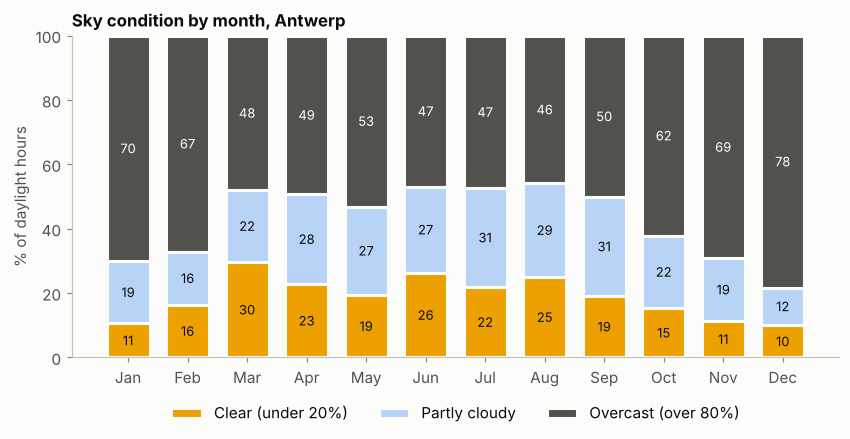

In [12]:
dl = one[one["shortwave_radiation"] > 5]
share = pd.DataFrame({
    "Clear (under 20%)": (dl["cloud_cover"] < 20).groupby(dl.index.month).mean(),
    "Partly cloudy": ((dl["cloud_cover"] >= 20) & (dl["cloud_cover"] <= 80)).groupby(dl.index.month).mean(),
    "Overcast (over 80%)": (dl["cloud_cover"] > 80).groupby(dl.index.month).mean(),
}) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
bottom = np.zeros(len(share))
for (name, vals), color in zip(share.items(), [YELLOW, BLUE_LIGHT, INK2]):
    ax.bar(share.index, vals, bottom=bottom, color=color, width=0.72, edgecolor=SURFACE, linewidth=2, label=name)
    for x, (b, v) in zip(share.index, zip(bottom, vals)):
        if v > 9:
            ax.text(x, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if color == INK2 else INK)
    bottom += vals.values
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("% of daylight hours"); ax.set_ylim(0, 100)
ax.set_title(f"Sky condition by month, {PROVINCE}")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.show()

### 4.4 Is the data consistent over time?

The file comes from one named weather model, ECMWF IFS HRES, for the whole period. An earlier download left the model choice to Open-Meteo, which switched from ECMWF to the Dutch KNMI model on 26 June 2024. Wind and cloud then changed level for reasons unrelated to the weather. This section checks that the single-model file does not show such a break.

The test: a 12-month rolling mean removes the seasons, so each line should be roughly flat. A step is a warning sign. The table compares two season-balanced windows of two years each.

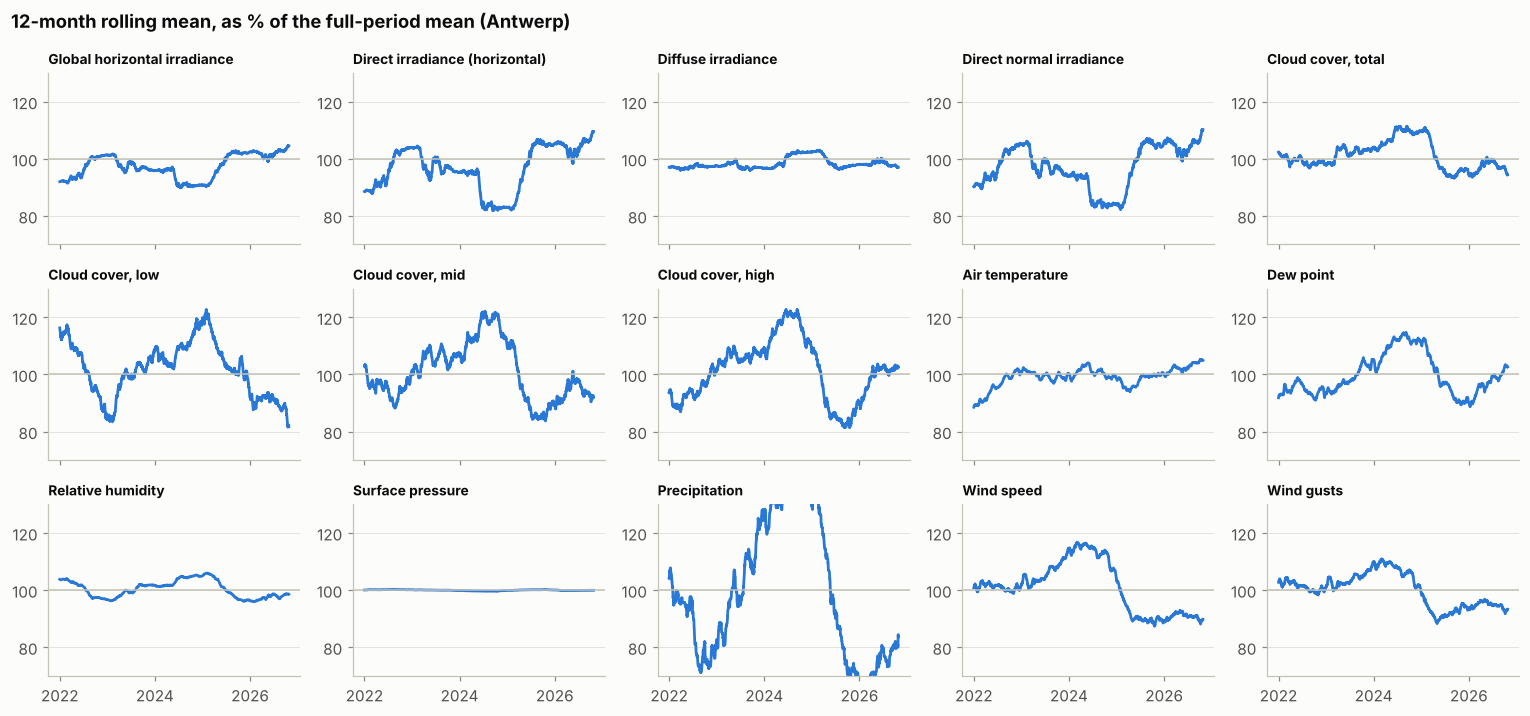

,Jul 2022 to Jun 2024,Jul 2024 to Jun 2026,change %
Precipitation (mm),0.12,0.08,-30.11
Wind speed (km/h),14.05,11.61,-17.39
"Cloud cover, mid (%)",35.79,29.65,-17.17
"Cloud cover, high (%)",46.54,38.98,-16.25
Wind gusts (km/h),27.73,24.48,-11.71
Direct normal irradiance (W/m²),148.11,164.62,11.14
Direct irradiance (horizontal) (W/m²),75.66,83.77,10.72
"Cloud cover, total (%)",69.87,64.40,-7.83
Dew point (°C),7.97,7.44,-6.55
"Cloud cover, low (%)",35.33,33.03,-6.50


In [13]:
allarea = wx.groupby("time")[cols].mean()
roll = allarea.rolling(24 * 365, min_periods=24 * 365).mean()
check = [c for c in cols if c != "wind_direction_10m"]

fig, axes = plt.subplots(3, 5, figsize=(14, 6.6), sharex=True)
for ax, c in zip(axes.ravel(), check):
    r = roll[c].dropna()
    ax.plot(r.index, r / allarea[c].mean() * 100, color=BLUE)
    ax.axhline(100, color=AXIS, linewidth=1)
    ax.set_ylim(70, 130)
    ax.set_title(VARIABLES[c][0], fontsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(check):]:
    ax.set_visible(False)
fig.suptitle(f"12-month rolling mean, as % of the full-period mean ({PROVINCE})", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

before = allarea.loc["2022-07-01":"2024-06-30", check].mean()
after = allarea.loc["2024-07-01":"2026-06-30", check].mean()
shift = pd.DataFrame({"Jul 2022 to Jun 2024": before, "Jul 2024 to Jun 2026": after,
                      "change %": (after / before - 1) * 100})
shift.index = [label(c) for c in check]
shift.sort_values("change %", key=abs, ascending=False)

Weather does differ from one two-year window to the next, so changes of a few percent are normal. A change of 20% or more appearing as a step would point to a change in the source. ECMWF also upgrades its model from time to time, which can cause smaller shifts.

## 5. A sample week, all variables

One week at hourly detail. Each panel groups variables that share a unit, so no panel has two scales.

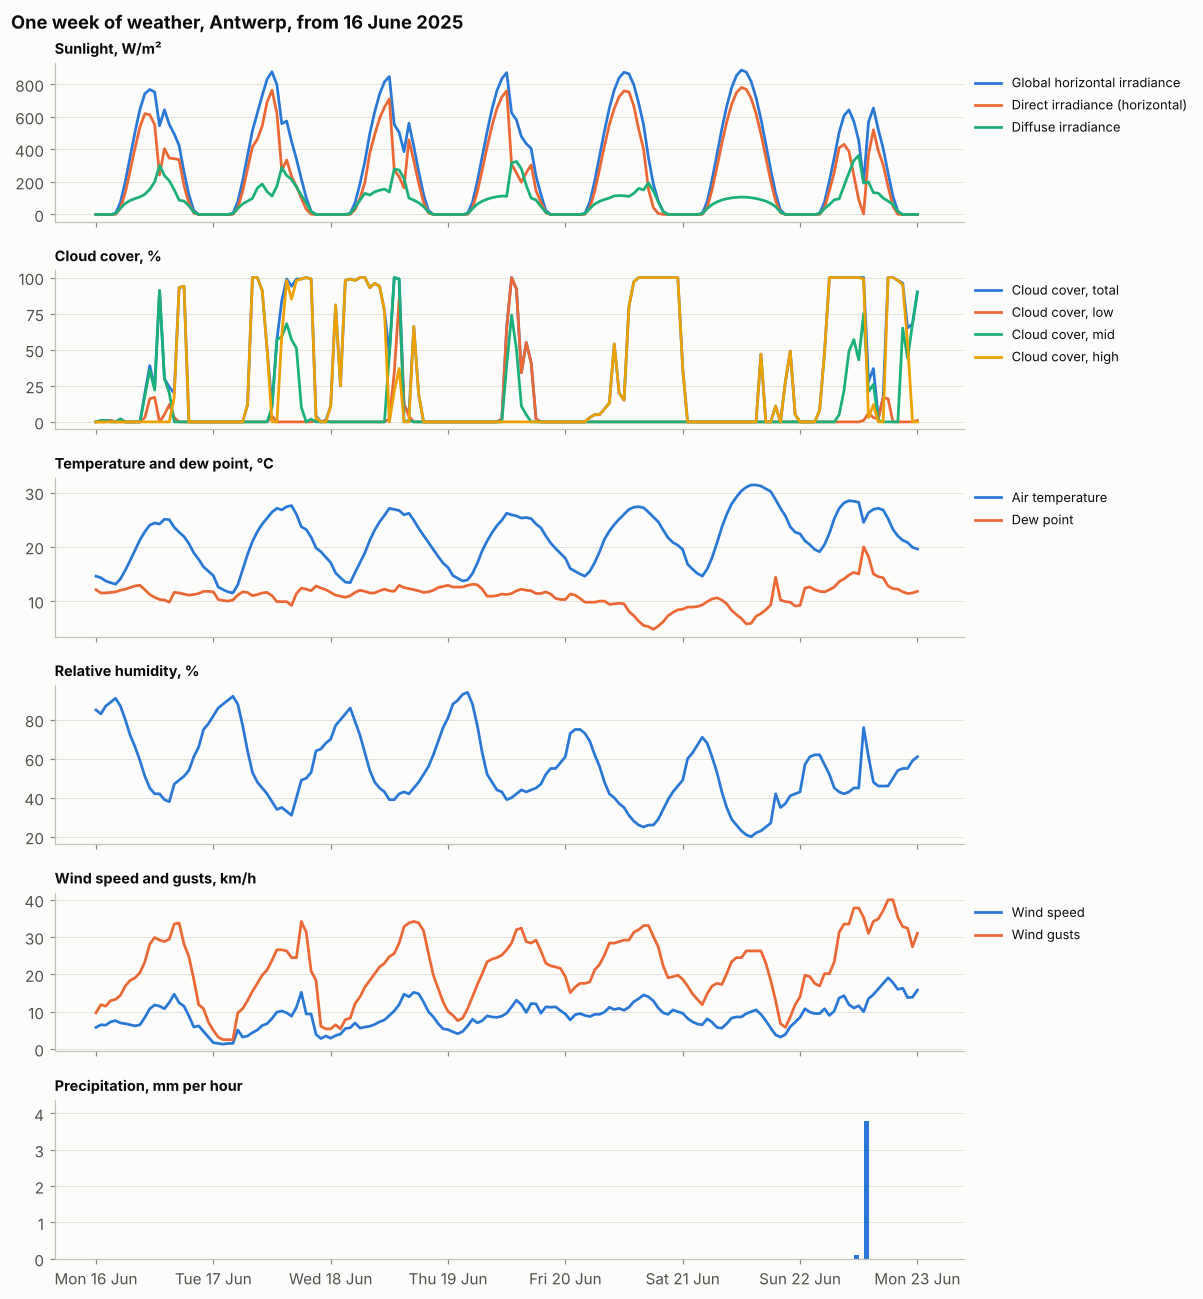

In [14]:
start = pd.Timestamp(WEEK_START, tz="UTC")
week = one.loc[start: start + pd.Timedelta(days=7)]

groups = [
    ("Sunlight, W/m²", ["shortwave_radiation", "direct_radiation", "diffuse_radiation"]),
    ("Cloud cover, %", ["cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high"]),
    ("Temperature and dew point, °C", ["temperature_2m", "dew_point_2m"]),
    ("Relative humidity, %", ["relative_humidity_2m"]),
    ("Wind speed and gusts, km/h", ["wind_speed_10m", "wind_gusts_10m"]),
    ("Precipitation, mm per hour", ["precipitation"]),
]
groups = [(t, [c for c in cs if c in cols]) for t, cs in groups]
groups = [(t, cs) for t, cs in groups if cs]
colors = [BLUE, ORANGE, AQUA, YELLOW]

fig, axes = plt.subplots(len(groups), 1, figsize=(11, 2.0 * len(groups)), sharex=True)
for ax, (title, cs) in zip(axes, groups):
    if cs == ["precipitation"]:
        ax.bar(week.index, week["precipitation"], width=1 / 24, color=BLUE, align="edge")
        ax.set_ylim(0, max(1.0, week["precipitation"].max() * 1.15))
        if week["precipitation"].sum() == 0:
            ax.text(0.5, 0.5, "No rain this week", transform=ax.transAxes, ha="center", va="center", color=MUTED)
    else:
        for c, color in zip(cs, colors):
            ax.plot(week.index, week[c], color=color, label=VARIABLES[c][0])
        if len(cs) > 1:
            ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle(f"One week of weather, {PROVINCE}, from {start:%d %B %Y}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

## 6. The working area against the others

This is the one section that uses every area in the file. It shows where the working area sits among the others, which matters later if the model is extended beyond one province.

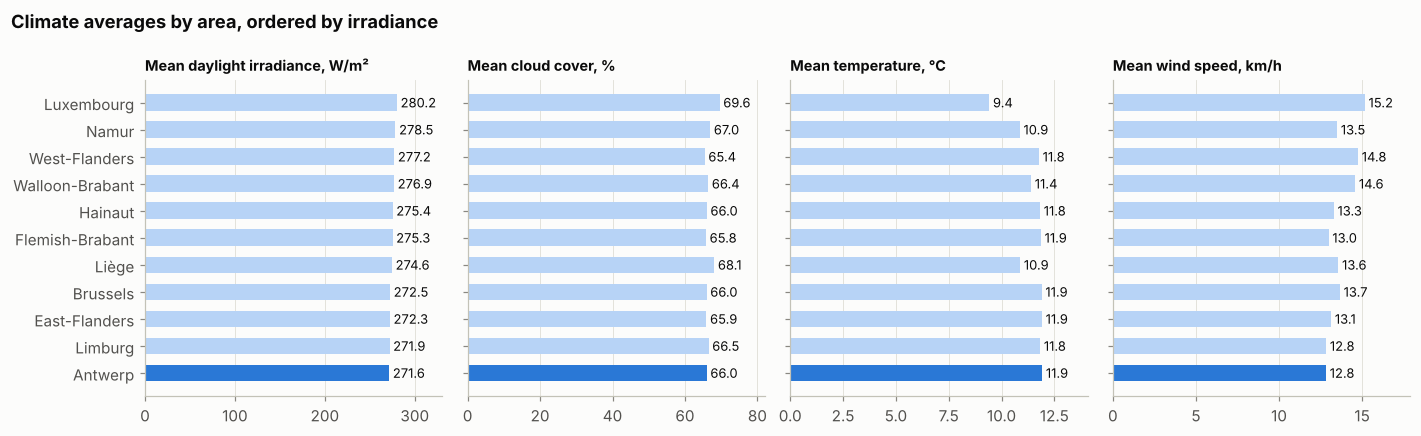

In [15]:
by_region = wx_all.groupby("region")[cols].mean()
by_region["ghi_daylight"] = wx_all[wx_all["shortwave_radiation"] > 5].groupby("region")["shortwave_radiation"].mean()
show = [("ghi_daylight", "Mean daylight irradiance, W/m²"), ("cloud_cover", "Mean cloud cover, %"),
        ("temperature_2m", "Mean temperature, °C"), ("wind_speed_10m", "Mean wind speed, km/h")]

fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharey=True)
order = by_region["ghi_daylight"].sort_values().index
for ax, (c, title) in zip(axes, show):
    v = by_region.loc[order, c]
    ax.barh(order, v, color=[BLUE if r == PROVINCE else BLUE_LIGHT for r in order], height=0.62)
    for y, x in enumerate(v):
        ax.text(x, y, f" {x:.1f}", va="center", fontsize=8.5, color=INK)
    lo, hi = v.min(), v.max()
    ax.set_xlim(0, hi * 1.18)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("Climate averages by area, ordered by irradiance", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

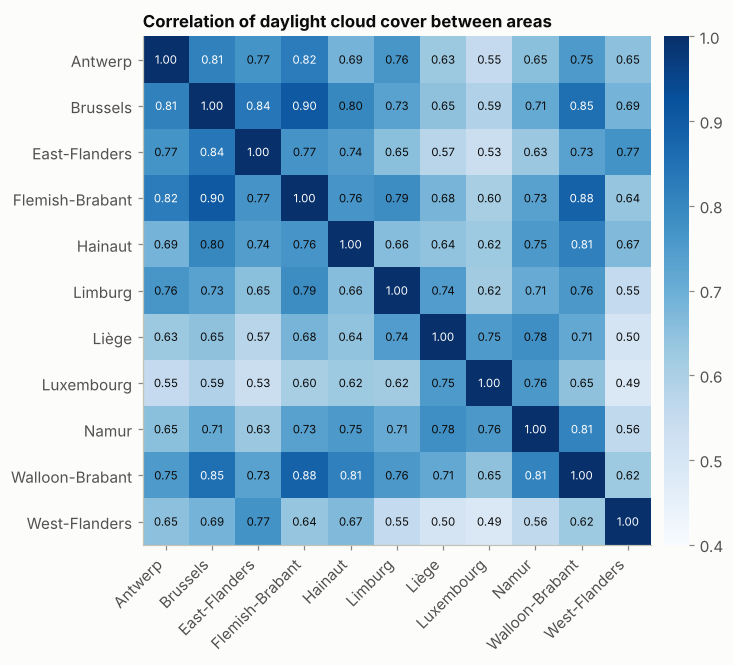

Closest to Antwerp:  Flemish-Brabant (0.82)
Furthest from Antwerp: Luxembourg (0.55)


In [16]:
# How closely do the areas move together? Correlation of hourly cloud cover between areas.
# (Cloud is used, not irradiance: irradiance correlates near 1 everywhere just because the sun rises for all.)
wide = wx_all[wx_all["shortwave_radiation"] > 5].pivot(index="time", columns="region", values="cloud_cover")
corr = wide.corr()

fig, ax = plt.subplots(figsize=(7.4, 6))
im = ax.imshow(corr.values, cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if corr.values[i, j] > 0.8 else INK)
ax.set_title("Correlation of daylight cloud cover between areas")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.outline.set_visible(False)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
mine = corr[PROVINCE].drop(PROVINCE).sort_values(ascending=False)
print(f"Closest to {PROVINCE}:  {mine.index[0]} ({mine.iloc[0]:.2f})")
print(f"Furthest from {PROVINCE}: {mine.index[-1]} ({mine.iloc[-1]:.2f})")

## 7. How the features relate to each other

Correlation between the raw features in daylight hours, for the working area. Two uses:

- **Redundancy.** Pairs near +1 or -1 carry almost the same information. Tree models cope with that, but linear models become unstable and feature importance gets split between the twins.
- **Report material.** This supports the data description section.

Wind direction is left out, since it is a circular variable (359° and 1° are neighbours) and an ordinary correlation would mislead.

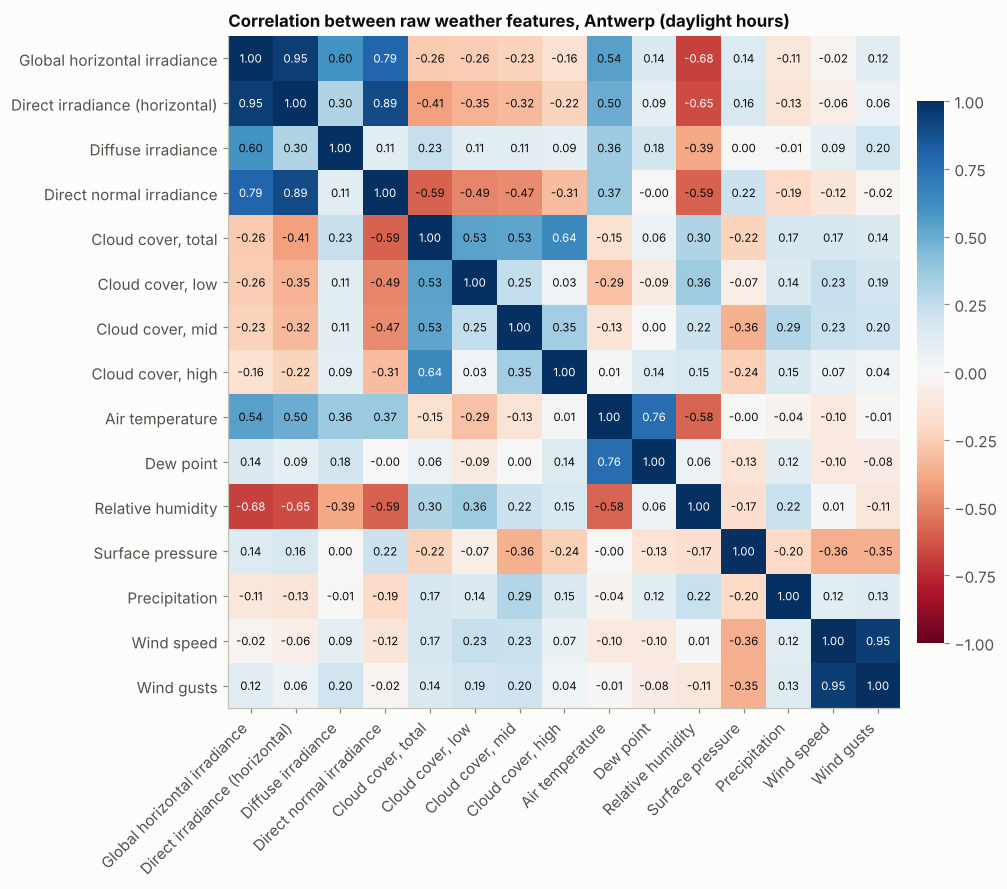

Pairs with correlation beyond ±0.8:
  Wind speed  and  Wind gusts:  +0.95
  Global horizontal irradiance  and  Direct irradiance (horizontal):  +0.95
  Direct irradiance (horizontal)  and  Direct normal irradiance:  +0.89


In [17]:
feat = [c for c in cols if c != "wind_direction_10m"]
fc = wx.loc[wx["shortwave_radiation"] > 5, feat].corr()
names = [VARIABLES[c][0] for c in feat]

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(fc.values, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat)), names, rotation=45, ha="right"); ax.set_yticks(range(len(feat)), names)
for i in range(len(feat)):
    for j in range(len(feat)):
        v = fc.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else INK)
ax.set_title(f"Correlation between raw weather features, {PROVINCE} (daylight hours)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02, shrink=0.8); cb.outline.set_visible(False)
plt.show()

pairs = fc.where(np.triu(np.ones(fc.shape, bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
print("Pairs with correlation beyond ±0.8:")
for (a, b), v in strong.items():
    print(f"  {VARIABLES[a][0]}  and  {VARIABLES[b][0]}:  {v:+.2f}")

## What to take from this

Fill this in from the outputs above:

- **Completeness:** hours present, missing values, and any days with implausible values (section 2).
- **Seasonality:** the size of the summer to winter swing in irradiance, and how often the sky is overcast (section 4).
- **Neighbours:** which areas have weather closest to the working area (section 6).
- **Redundancy:** which features duplicate each other (section 7).

**Reminder on what this data is.** It comes from Open-Meteo's archive of past ECMWF IFS HRES forecasts, which stitches together the first hours of each model run. It is closer to the weather that happened than a true day-ahead forecast would be.